# Filtro de Kalman em 2D: passo a passo

Rastreamos a posição e a velocidade de um objeto no plano $(X, Y)$ com o modelo de **velocidade constante**.

Estado: $\mathbf{x} = [p_x,\ p_y,\ v_x,\ v_y]^T$. O sensor (GPS) mede apenas a posição.

O ciclo tem duas fases:

**Previsão**
1. $\hat{x}_k^- = F\,\hat{x}_{k-1}$
2. $P_k^- = F\,P_{k-1}\,F^T + Q$

**Atualização**
3. $K_k = P_k^- H^T (H P_k^- H^T + R)^{-1}$
4. $\hat{x}_k = \hat{x}_k^- + K_k (z_k - H\hat{x}_k^-)$
5. $P_k = (I - K_k H)\,P_k^-$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

## 1. Parâmetros iniciais ($k=0$)

In [2]:
dt = 1.0

x0 = np.array([[0.0], [0.0], [1.0], [2.0]])  # [px, py, vx, vy]
P0 = np.eye(4)

F = np.array([[1, 0, dt, 0],
              [0, 1, 0, dt],
              [0, 0, 1, 0],
              [0, 0, 0, 1]], dtype=float)

H = np.array([[1, 0, 0, 0],
              [0, 1, 0, 0]], dtype=float)

Q = 0.1 * np.eye(4)
R = 0.5 * np.eye(2)

z1 = np.array([[1.2], [2.1]])  # leitura do sensor em k = 1
I = np.eye(4)

print('x0 =\n', x0.ravel())
print('P0 =\n', P0)

x0 =
 [0. 0. 1. 2.]
P0 =
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]


## 2. Fase 1: Previsão (Time Update)

### Passo 1: estado a priori
$\hat{x}_1^- = F\,x_0$

In [3]:
x_prior = F @ x0
print('x_prior =', x_prior.ravel())  # esperado: [1, 2, 1, 2]

x_prior = [1. 2. 1. 2.]


### Passo 2: covariância a priori
$P_1^- = F P_0 F^T + Q$. A incerteza cresce com o tempo e com o ruído do processo.

In [4]:
P_prior = F @ P0 @ F.T + Q
print(P_prior)  # diagonal [2.1, 2.1, 1.1, 1.1], acoplamento pos-vel = 1.0

[[2.1 0.  1.  0. ]
 [0.  2.1 0.  1. ]
 [1.  0.  1.1 0. ]
 [0.  1.  0.  1.1]]


## 3. Fase 2: Atualização (Measurement Update)

### Passo 3: ganho de Kalman
$S = H P^- H^T + R$ e $K = P^- H^T S^{-1}$. $K$ é $4\times2$.

In [5]:
S = H @ P_prior @ H.T + R
K = P_prior @ H.T @ np.linalg.inv(S)
print('S =\n', S)  # 2.6 na diagonal
print('K =\n', K)  # ~0.808 (posição) e ~0.385 (velocidade)

S =
 [[2.6 0. ]
 [0.  2.6]]
K =
 [[0.808 0.   ]
 [0.    0.808]
 [0.385 0.   ]
 [0.    0.385]]


### Passo 4: estado a posteriori
Inovação: $y = z_1 - H\hat{x}_1^-$. Correção: $\hat{x}_1 = \hat{x}_1^- + K y$.

In [6]:
y = z1 - H @ x_prior
correcao = K @ y
x1 = x_prior + correcao

print('inovação  =', y.ravel())         # [0.2, 0.1]
print('correção  =', correcao.ravel())  # [0.162, 0.081, 0.077, 0.038]
print('x1        =', x1.ravel())        # [1.162, 2.081, 1.077, 2.038]

inovação  = [0.2 0.1]
correção  = [0.162 0.081 0.077 0.038]
x1        = [1.162 2.081 1.077 2.038]


### Passo 5: covariância a posteriori
$P_1 = (I - K H) P_1^-$. A incerteza das posições diminui.

In [7]:
P1 = (I - K @ H) @ P_prior
print(P1)
print('\nVariância de px: antes =', P_prior[0, 0], '| depois =', round(P1[0, 0], 3))

[[0.404 0.    0.192 0.   ]
 [0.    0.404 0.    0.192]
 [0.192 0.    0.715 0.   ]
 [0.    0.192 0.    0.715]]

Variância de px: antes = 2.1 | depois = 0.404


## 4. O ciclo contínuo

Depois do passo 5, $\hat{x}_k$ e $P_k$ viram $\hat{x}_{k-1}$ e $P_{k-1}$ do próximo ciclo. Encapsulamos tudo em duas funções.

In [8]:
def predict(x, P, F, Q):
    x_prior = F @ x
    P_prior = F @ P @ F.T + Q
    return x_prior, P_prior


def update(x_prior, P_prior, z, H, R):
    S = H @ P_prior @ H.T + R
    K = P_prior @ H.T @ np.linalg.inv(S)
    x = x_prior + K @ (z - H @ x_prior)
    P = (np.eye(len(x)) - K @ H) @ P_prior
    return x, P, K


# Reproduz o resultado do passo a passo
xp, Pp = predict(x0, P0, F, Q)
x1_f, P1_f, _ = update(xp, Pp, z1, H, R)
print(np.allclose(x1_f, x1), np.allclose(P1_f, P1))

True True


## 5. Simulação: trajetória real, GPS ruidoso e estimativa

Geramos um objeto com velocidade constante $(1, 2)$ m/s. O GPS tem desvio-padrão $\sqrt{0.5}$. O filtro começa com uma estimativa inicial errada na velocidade.

In [9]:
rng = np.random.default_rng(42)
n = 30

# Trajetória verdadeira
x_true = np.zeros((n + 1, 4, 1))
x_true[0] = x0
for k in range(1, n + 1):
    x_true[k] = F @ x_true[k - 1]

# Medições ruidosas de posição
zs = [H @ x_true[k] + rng.normal(0, np.sqrt(R[0, 0]), (2, 1)) for k in range(1, n + 1)]

# Filtro com chute inicial ruim
x = np.array([[0.0], [0.0], [0.0], [0.0]])
P = np.eye(4) * 5
est = [x]
for z in zs:
    x_p, P_p = predict(x, P, F, Q)
    x, P, K = update(x_p, P_p, z, H, R)
    est.append(x)

est = np.array(est)
meas = np.array(zs)

rmse_gps = np.sqrt(np.mean((meas[:, :, 0] - x_true[1:, :2, 0]) ** 2))
rmse_kf = np.sqrt(np.mean((est[1:, :2, 0] - x_true[1:, :2, 0]) ** 2))
print(f'RMSE GPS bruto : {rmse_gps:.3f}')
print(f'RMSE Kalman    : {rmse_kf:.3f}')
print('Velocidade estimada final:', est[-1, 2:, 0], '(real: [1, 2])')

RMSE GPS bruto : 0.553
RMSE Kalman    : 0.406
Velocidade estimada final: [0.894 2.217] (real: [1, 2])


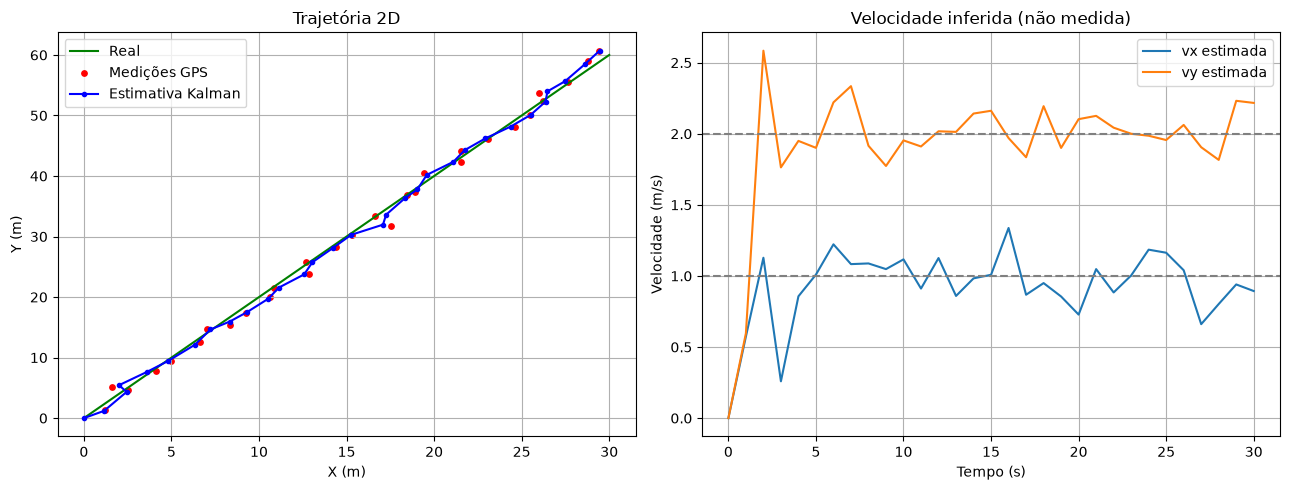

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].plot(x_true[:, 0, 0], x_true[:, 1, 0], 'g-', label='Real')
ax[0].scatter(meas[:, 0, 0], meas[:, 1, 0], c='r', s=15, label='Medições GPS')
ax[0].plot(est[:, 0, 0], est[:, 1, 0], 'b-o', ms=3, label='Estimativa Kalman')
ax[0].set_xlabel('X (m)'); ax[0].set_ylabel('Y (m)')
ax[0].set_title('Trajetória 2D'); ax[0].legend(); ax[0].grid(True)

t = np.arange(n + 1) * dt
ax[1].plot(t, est[:, 2, 0], label='vx estimada')
ax[1].plot(t, est[:, 3, 0], label='vy estimada')
ax[1].axhline(1.0, color='gray', ls='--'); ax[1].axhline(2.0, color='gray', ls='--')
ax[1].set_xlabel('Tempo (s)'); ax[1].set_ylabel('Velocidade (m/s)')
ax[1].set_title('Velocidade inferida (não medida)'); ax[1].legend(); ax[1].grid(True)

plt.tight_layout()
plt.show()

## Conclusões

- O sensor mede só a posição, mas o filtro estima também a velocidade, pela correlação em $P$ (linhas 3 e 4 de $K$).
- A estimativa é menos ruidosa que o GPS bruto (RMSE menor).
- $Q$ maior faz o filtro confiar mais no sensor. $R$ maior faz confiar mais no modelo.